# 5. File distribution (descriptive)

**Purpose:** describe what was shot, not find groups. Each burst counts as one image.

**Burst rule:** consecutive files in the same folder with an identical `DateTimeOriginal` (the same second) form one burst. The first frame represents it. The camera's sequence tags are not used because they disagree with the timestamps on this camera.

**Known limits:** a burst that crosses a second boundary is split in two, and two single shots taken in the same second are merged.

**Data:** served from the `.cache/` folder when the cache is less than one day old, otherwise rescanned with exiftool. Change `DIRECTORY` and `DEPTH` below to point elsewhere.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent  # run from the notebooks/ folder
if not (ROOT / "focal_data.py").is_file():
    raise FileNotFoundError(f"focal_data.py not found in {ROOT}; run from notebooks/")
sys.path.insert(0, str(ROOT))

from focal_data import group_bursts, load_records

DIRECTORY, DEPTH = r"D:\DCIM", 1
records = load_records(DIRECTORY, DEPTH)
bursts = group_bursts(records)


## Summary

In [2]:
summary = pd.Series({
    "Image files": len(records),
    "Bursts (each counted once)": len(bursts),
    "Single shots": int((bursts.frames == 1).sum()),
    "Multi-frame bursts": int((bursts.frames > 1).sum()),
    "Frames inside multi-frame bursts": int(bursts.loc[bursts.frames > 1, "frames"].sum()),
    "Focal length range (mm)": f"{bursts.focal_mm.min():.0f}-{bursts.focal_mm.max():.0f}",
})
summary.to_frame("value")

,value
Image files,885
Bursts (each counted once),877
Single shots,872
Multi-frame bursts,5
Frames inside multi-frame bursts,13
Focal length range (mm),18-135


## Focal length distribution
One bar per 1 mm, counting each burst once.

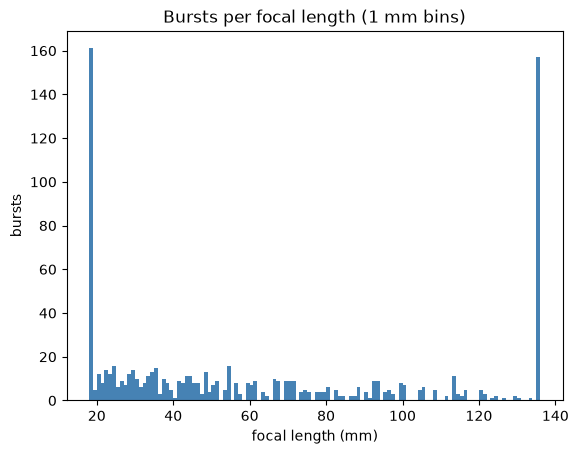

,bursts
focal length (mm),
18.0,161
135.0,157
54.0,16
24.0,16
35.0,15
22.0,14
29.0,14
34.0,13
48.0,13


In [3]:
edges = np.arange(np.floor(bursts.focal_mm.min()), np.ceil(bursts.focal_mm.max()) + 2, 1)
plt.hist(bursts.focal_mm, bins=edges, color="steelblue")
plt.xlabel("focal length (mm)")
plt.ylabel("bursts")
plt.title("Bursts per focal length (1 mm bins)")
plt.show()

bursts.focal_mm.value_counts().head(10).rename_axis("focal length (mm)").to_frame("bursts")

## Before and after burst merging
Compares every image with the merged view. If merging changes little, the burst rule does not affect the conclusions for this folder.

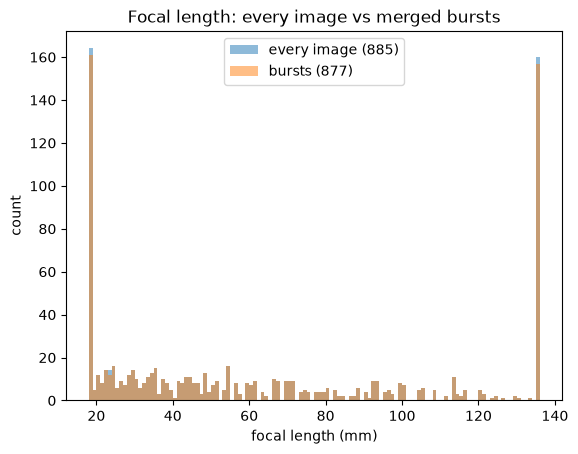

In [4]:
edges = np.arange(np.floor(records.focal_mm.min()), np.ceil(records.focal_mm.max()) + 2, 1)
plt.hist(records.focal_mm, bins=edges, alpha=0.5, label=f"every image ({len(records)})")
plt.hist(bursts.focal_mm, bins=edges, alpha=0.5, label=f"bursts ({len(bursts)})")
plt.xlabel("focal length (mm)")
plt.ylabel("count")
plt.title("Focal length: every image vs merged bursts")
plt.legend()
plt.show()

### Images merged away per focal length
Images minus bursts for each focal length. Only focal lengths where merging removed something are listed.

In [5]:
comparison = pd.DataFrame({
    "images": records.focal_mm.value_counts(),
    "bursts": bursts.focal_mm.value_counts(),
}).fillna(0).astype(int)
comparison["merged away"] = comparison["images"] - comparison["bursts"]
print(f"Total images merged away: {comparison['merged away'].sum()}")
comparison[comparison["merged away"] > 0].sort_values("merged away", ascending=False).head(10)

Total images merged away: 8


,images,bursts,merged away
focal_mm,,,
18.0,164,161,3
135.0,160,157,3
23.0,14,12,2


## Focal length bands
Conventional photographic ranges, not discovered groups. A value exactly on an edge (for example 35 mm) goes to the lower band.

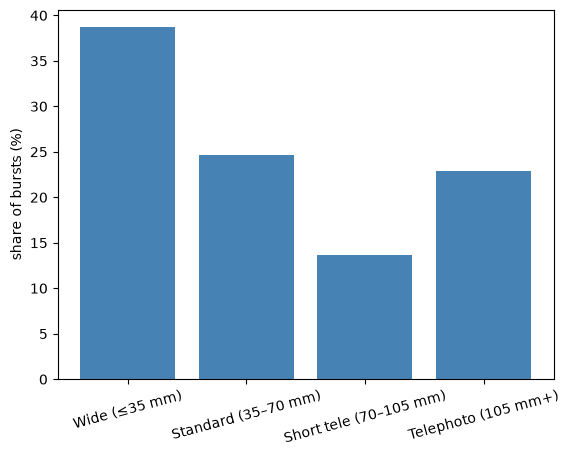

,bursts,share %
focal_mm,,
Wide (≤35 mm),339,38.7
Standard (35–70 mm),217,24.7
Short tele (70–105 mm),120,13.7
Telephoto (105 mm+),201,22.9


In [6]:
BANDS = ["Wide (≤35 mm)", "Standard (35–70 mm)", "Short tele (70–105 mm)", "Telephoto (105 mm+)"]
band = pd.cut(bursts.focal_mm, bins=[0, 35, 70, 105, 200], labels=BANDS)
band_table = band.value_counts(sort=False).rename("bursts").to_frame()
band_table["share %"] = (band_table["bursts"] / band_table["bursts"].sum() * 100).round(1)

plt.bar(band_table.index.astype(str), band_table["share %"], color="steelblue")
plt.ylabel("share of bursts (%)")
plt.xticks(rotation=15)
plt.show()
band_table

## Band shares: every image vs bursts
The same bands as above, before and after merging.

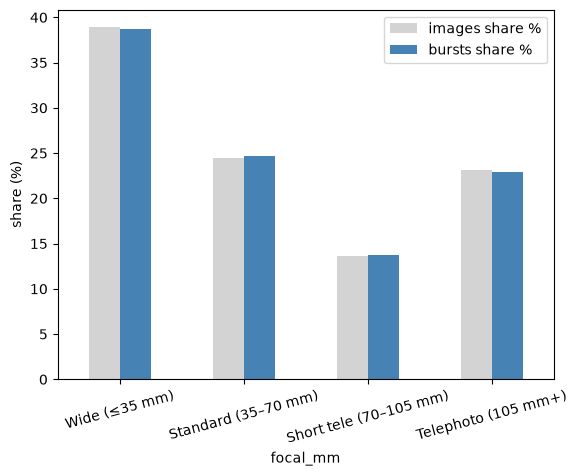

,images count,images share %,bursts count,bursts share %
focal_mm,,,,
Wide (≤35 mm),344,38.9,339,38.7
Standard (35–70 mm),217,24.5,217,24.7
Short tele (70–105 mm),120,13.6,120,13.7
Telephoto (105 mm+),204,23.1,201,22.9


In [7]:
def band_shares(values):
    """Return the count and share (%) of values in each focal length band."""
    counts = pd.cut(values, bins=[0, 35, 70, 105, 200], labels=BANDS).value_counts(sort=False)
    return pd.DataFrame({"count": counts, "share %": (counts / counts.sum() * 100).round(1)})

band_compare = band_shares(records.focal_mm).add_prefix("images ").join(
    band_shares(bursts.focal_mm).add_prefix("bursts "))
band_compare[["images share %", "bursts share %"]].plot.bar(rot=15, color=["lightgray", "steelblue"])
plt.ylabel("share (%)")
plt.show()
band_compare

## Cumulative distribution of burst focal lengths
The share of bursts at or below each focal length. Markers show the quartiles.

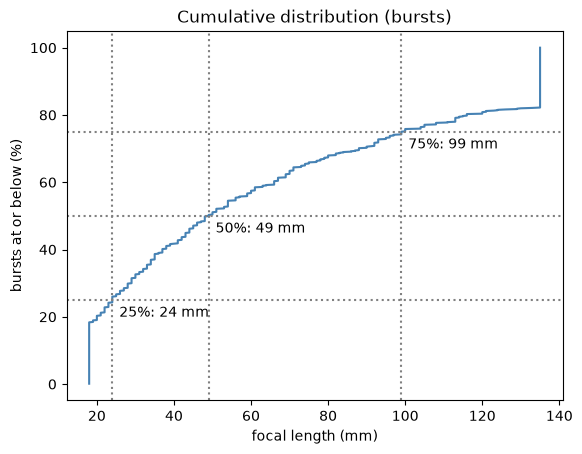

In [8]:
ordered = np.sort(bursts.focal_mm.to_numpy())
cumulative = np.arange(1, len(ordered) + 1) / len(ordered) * 100
plt.plot(ordered, cumulative, color="steelblue")
for q in [25, 50, 75]:
    value = np.percentile(ordered, q)
    plt.axhline(q, ls=":", color="gray")
    plt.axvline(value, ls=":", color="gray")
    plt.annotate(f"{q}%: {value:.0f} mm", (value, q), xytext=(5, -12), textcoords="offset points")
plt.xlabel("focal length (mm)")
plt.ylabel("bursts at or below (%)")
plt.title("Cumulative distribution (bursts)")
plt.show()

## Multi-frame bursts
Every burst with more than one frame. These are the only places where merging changes the count, so check them by hand.

In [9]:
bursts[bursts.frames > 1][["file", "focal_mm", "datetime", "frames"]].reset_index(drop=True)

,file,focal_mm,datetime,frames
0,D:/DCIM/13561011/DSC02162.ARW,23.0,2026:10:11 08:40:34,3
1,D:/DCIM/15061103/DSC03137.ARW,135.0,2026:11:03 12:17:54,2
2,D:/DCIM/15061103/DSC03139.ARW,135.0,2026:11:03 12:17:55,3
3,D:/DCIM/15061103/DSC03142.ARW,18.0,2026:11:03 12:18:20,3
4,D:/DCIM/15061103/DSC03145.ARW,18.0,2026:11:03 12:18:21,2


## Bursts per day
When the photos were taken, one bar per calendar day.

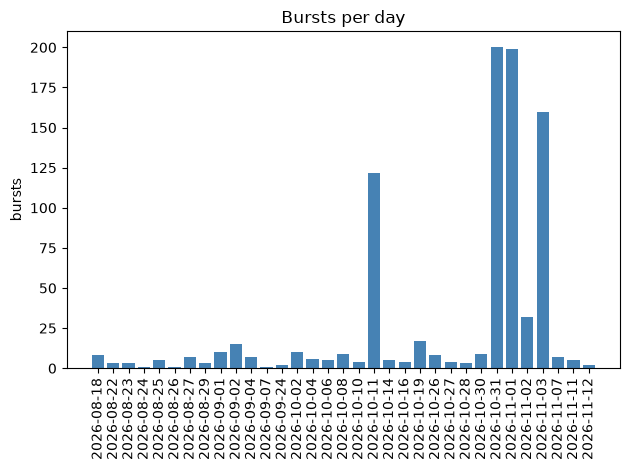

,bursts
day,
2026-08-18,8
2026-08-22,3
2026-08-23,3
2026-08-24,1
2026-08-25,5
2026-08-26,1
2026-08-27,7
2026-08-29,3
2026-09-01,10


In [10]:
day = pd.to_datetime(bursts["datetime"], format="%Y:%m:%d %H:%M:%S").dt.date
per_day = day.value_counts().sort_index()

plt.bar(per_day.index.astype(str), per_day.values, color="steelblue")
plt.ylabel("bursts")
plt.xticks(rotation=90)
plt.title("Bursts per day")
plt.tight_layout()
plt.show()
per_day.rename_axis("day").to_frame("bursts")

## Preliminary analysis: takeaways
Figures from this run (`D:\DCIM`, depth 1, 885 images). They describe this folder only and change if the folder changes.

1. **Merging barely changes the picture.** Only 8 of 885 images merged into bursts (877 bursts). Band shares move by at most 0.2 percentage points. The burst rule matters only for the five multi-frame bursts.
2. **Two peaks at the ends of the zoom.** 18 mm (18.4% of bursts) and 135 mm (17.9%) together make up over a third of bursts. They match the ends of the 18–135 mm lens, so they may be zoom stops rather than deliberate framings. Check a sample of these photos before reading them as a preference.
3. **Wide shooting dominates by band.** Wide (≤35 mm) 38.7%, standard (35–70 mm) 24.7%, short tele (70–105 mm) 13.7%, telephoto (105 mm+) 22.9%.
4. **Typical focal length is 49 mm.** Half of bursts are at or below 49 mm. The middle half lies between 24 and 99 mm.
5. **Shooting is concentrated on a few days.** 31 October, 1 November and 3 November hold 559 of 877 bursts (64%). 11 October adds 122 more. The other days have between 1 and 32 bursts each.
6. **Known limit.** The bursts at 12:17:54 and 12:17:55 (both 135 mm) are counted as two bursts under the same-second rule. They may be one burst that crossed a second boundary. The multi-frame bursts are few, so this affects the counts only slightly.

**Next:** decide whether the 18 mm and 135 mm peaks are zoom stops. That decides whether the preference analysis should exclude them.